# Joint Distributions

This notebook accompanies the note [Joint Distributions](../../notes/joint_distributions_and_covariance/joint_distributions.md). We start from a small joint pmf, derive marginal and conditional distributions, test independence, and then check a continuous example numerically.

The joint pmf of $X\in\{0,1\}$ and $Y\in\{0,1,2\}$ is stored as a matrix whose rows index $X$ and columns index $Y$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)

joint = np.array([[0.10, 0.15, 0.05],
                  [0.10, 0.20, 0.40]])
x_vals = np.array([0, 1])
y_vals = np.array([0, 1, 2])

print(joint)
print("Total probability:", joint.sum())

[[0.1  0.15 0.05]
 [0.1  0.2  0.4 ]]
Total probability: 1.0


## Marginal and conditional distributions

Marginals come from summing the joint pmf over the other variable: $p_X(x)=\sum_y p(x,y)$. A conditional pmf divides a row (or column) by the corresponding marginal.

In [2]:
px = joint.sum(axis=1)
py = joint.sum(axis=0)
print("p_X:", px)
print("p_Y:", py)

for xv in x_vals:
    cond = joint[xv] / px[xv]
    print(f"p(Y | X={xv}) =", np.round(cond, 4), " E[Y|X={}] = {:.4f}".format(xv, cond @ y_vals))

ey = y_vals @ py
total_exp = sum((joint[i] / px[i]) @ y_vals * px[i] for i in range(2))
print("E[Y] =", ey, " law of total expectation:", total_exp)

p_X: [0.3 0.7]
p_Y: [0.2  0.35 0.45]
p(Y | X=0) = [0.3333 0.5    0.1667]  E[Y|X=0] = 0.8333
p(Y | X=1) = [0.1429 0.2857 0.5714]  E[Y|X=1] = 1.4286
E[Y] = 1.25  law of total expectation: 1.25


## Moments, covariance and correlation

Expectations of functions of $(X,Y)$ are sums over the whole table. Here $\operatorname{Cov}(X,Y)=E[XY]-E[X]E[Y]$. We confirm the hand calculation by sampling from the joint distribution.

In [3]:
ex = x_vals @ px
exy = np.sum(joint * np.outer(x_vals, y_vals))
var_x = ((x_vals - ex) ** 2) @ px
var_y = ((y_vals - ey) ** 2) @ py
cov = exy - ex * ey
corr = cov / np.sqrt(var_x * var_y)
print(f"E[X]={ex:.3f} E[Y]={ey:.3f} E[XY]={exy:.3f}")
print(f"Var X={var_x:.4f} Var Y={var_y:.4f} Cov={cov:.4f} Corr={corr:.4f}")

# Monte Carlo check: draw cells according to the joint pmf
idx = rng.choice(joint.size, size=200_000, p=joint.ravel())
xs, ys = x_vals[idx // 3], y_vals[idx % 3]
print("Simulated Cov:", round(np.cov(xs, ys)[0, 1], 4), " Simulated corr:", round(np.corrcoef(xs, ys)[0, 1], 4))

E[X]=0.700 E[Y]=1.250 E[XY]=1.000
Var X=0.2100 Var Y=0.5875 Cov=0.1250 Corr=0.3559
Simulated Cov: 0.125  Simulated corr: 0.3565


## Independence

$X$ and $Y$ are independent only if every cell equals the product of its marginals. We compare the joint table with $p_X(x)p_Y(y)$.

Product of marginals:
 [[0.06  0.105 0.135]
 [0.14  0.245 0.315]]
Cell-wise differences:
 [[ 0.04   0.045 -0.085]
 [-0.04  -0.045  0.085]]
Independent? False


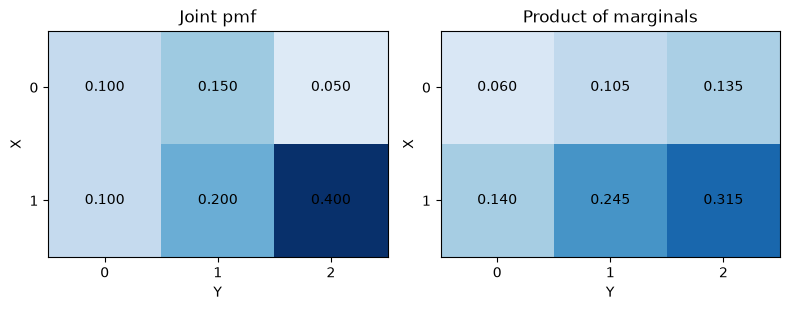

In [4]:
product = np.outer(px, py)
print("Product of marginals:\n", np.round(product, 3))
print("Cell-wise differences:\n", np.round(joint - product, 3))
print("Independent?", np.allclose(joint, product))

fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
for ax, tab, title in zip(axes, [joint, product], ["Joint pmf", "Product of marginals"]):
    im = ax.imshow(tab, cmap="Blues", vmin=0, vmax=0.4)
    ax.set_xticks(range(3)); ax.set_yticks(range(2))
    ax.set_xlabel("Y"); ax.set_ylabel("X"); ax.set_title(title)
    for i in range(2):
        for j in range(3):
            ax.text(j, i, f"{tab[i, j]:.3f}", ha="center", va="center")
plt.tight_layout(); plt.show()

## A continuous joint density

For $f(x,y)=x+y$ on the unit square we integrate numerically with `scipy.integrate.dblquad` to confirm normalization, the marginal $f_X(x)=x+\tfrac12$ and $E[X]=7/12$.

In [5]:
from scipy import integrate

f = lambda y, x: x + y            # dblquad integrates over y first
total, _ = integrate.dblquad(f, 0, 1, 0, 1)
ex_cont, _ = integrate.dblquad(lambda y, x: x * f(y, x), 0, 1, 0, 1)
p_quarter, _ = integrate.dblquad(f, 0, 0.5, 0, 0.5)
print("Total probability:", round(total, 6))
print("E[X]:", round(ex_cont, 6), " 7/12 =", round(7 / 12, 6))
print("P(X<=.5, Y<=.5):", round(p_quarter, 6), " (1/8 =", 1 / 8, ")")

xg = np.linspace(0, 1, 5)
numeric_marginal = [integrate.quad(lambda y: xv + y, 0, 1)[0] for xv in xg]
print("Marginal check:", np.allclose(numeric_marginal, xg + 0.5))

Total probability: 1.0
E[X]: 0.583333  7/12 = 0.583333
P(X<=.5, Y<=.5): 0.125  (1/8 = 0.125 )
Marginal check: True
